# Aviso de unificação das mensalidades — ctasmart

Disparo do comunicado de unificação das mensalidades de aluguel e licenciamento, a partir de
`contato.financeiro@ctasmart.com.br`, para os clientes da aba **lista comunicado** da planilha
*unificações .xlsx*. Os e-mails dos clientes vêm só do cadastro do CIGAM no DW.

Repositório: https://github.com/yagoppereira/comunicacoes_financeiras

**Ordem:** 1 → 2 → 3 → 4 → 5 (teste) → 6 (produção). Para continuar outro dia: seção 7.

Nada é enviado nas seções 1 a 4.

## 0. Antes da primeira vez (fora do notebook)

- Crie uma **senha de app** na conta que vai enviar (https://myaccount.google.com/apppasswords — exige verificação em duas etapas).
  - Se `contato.financeiro@` tiver login próprio, crie nela.
  - Se for caixa compartilhada sem login, crie na sua conta e cadastre `contato.financeiro@` em
    Gmail → Configurações → Contas → "Enviar e-mail como". Sem isso o Gmail troca o remetente pela sua conta.
- Guarde a senha no Colab: ícone 🔑 na barra lateral → secret **`SMTP_FINANCEIRO`**, com acesso liberado a este notebook.
  Nunca cole a senha numa célula.
- A planilha precisa estar compartilhada com a conta Google que você usa no Colab.

## 1. Instalação e conexão

Abre o login do Google (BigQuery e Drive) e monta o Drive, onde ficam o log e a prévia.

Se você atualizar o código (`pull`) com a sessão aberta, reinicie a sessão
(Ambiente de execução → Reiniciar sessão): senão o Python continua usando a versão antiga.

In [1]:
!test -d comunicacoes_financeiras && git -C comunicacoes_financeiras pull -q || git clone -q https://github.com/yagoppereira/comunicacoes_financeiras.git
!pip install -q -r comunicacoes_financeiras/requirements.txt
import sys; sys.path.insert(0, "comunicacoes_financeiras")

import pandas as pd
from comunicacoes_financeiras import fluxo, envio
from comunicacoes_financeiras.campanha import Campanha
from google.colab import drive, userdata

bq = fluxo.conectar_colab()
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Configuração da campanha

O `id_campanha` é o que impede envio em dobro: mantenha o **mesmo id** até terminar esta rodada
(inclusive nos dias seguintes) e use um novo na próxima.

In [2]:
PARAM = dict(id_campanha="UNIF-2026-11-A", modelo="unificacao_contratos")
# opcional, para a caixa do financeiro receber cópia de todos:
# PARAM["copia_padrao"] = ("contato.financeiro@ctasmart.com.br",)

PLANILHA = "https://docs.google.com/spreadsheets/d/111fwG0ouHLTcxOFmzR2IhH0ADLcLy6Xf/edit"
ABA, COLUNA = "lista comunicado", "COD CIGAM"

PASTA = "/content/drive/MyDrive/comunicacoes_financeiras"
PREVIA = f"{PASTA}/previa_{PARAM['id_campanha']}.csv"
registro = envio.RegistroCSV(f"{PASTA}/log.csv")

## 3. Ler a lista e preparar — não envia nada

Lê os códigos da planilha, busca os e-mails no DW, junta cadastros com os mesmos destinatários
e salva a prévia no Drive. A tabela no fim mostra quem **não** vai receber e por quê.

Esperado com a lista de 28/10: 388 lidos, 31 repetidos, nenhum rejeitado, 338 e-mails.

In [3]:
lista = fluxo.ler_lista_planilha(PLANILHA, aba=ABA, coluna=COLUNA)

c = Campanha.ensaio(**PARAM)
previa, resolucao = fluxo.preparar(bq, c, lista)
fluxo.salvar_previa(previa, PREVIA)

pd.DataFrame(resolucao.rejeitados, columns=["entrada", "motivo"])

baixado do Drive: unificações .xlsx
899 código(s) lido(s) da aba 'lista comunicado' (0 linha(s) vazia(s) ignorada(s)).
Aviso de unificação das mensalidades — campanha UNIF-2026-11-A
Destinatários: contatos com recebeEmailNfe ou recebeEmailBoleto = S

859 cliente(s) com destinatário, 2060 e-mail(s).
39 linha(s) repetida(s) na lista, consideradas uma vez.
1 NÃO vão receber — confira antes de disparar:
   '1684': 001684 sem destinatário: 1 e-mail(s) no cadastro, todos com recebeEmailBoleto / recebeEmailNfe = N

820 e-mail(s) a enviar (1969 destinatário(s)).


,entrada,motivo
0,1684,001684 sem destinatário: 1 e-mail(s) no cadast...


## 4. Conferir

Um e-mail por linha. `qtd_cadastros` > 1 = um e-mail que cobre vários cadastros do mesmo grupo.

In [4]:
previa[["chave", "nome", "qtd_cadastros", "para", "qtd_para"]]

,chave,nome,qtd_cadastros,para,qtd_para
0,005115,3 X PRODUTOS QUIMICOS LTDA,1,adm.logistica@triex.ind.br; financeiro@triex.i...,3
1,004221,6M TRIAGEM E TRANSBORDO LTDA,1,compras.jmscunha@gmail.com; michelecunha.jms@g...,2
2,005107,A DOS SANTOS MELO CIMENTO LTDA,1,financeiro3.cimentomelo@gmail.com,1
3,005147,CARLA ROSANA DE FREITAS,1,financeiroagrobelavista@gmail.com,1
4,005194,AMAZONIA MUCAJAI MINERACAO LTDA,1,financeiro@ebam.com.br; ti@ebam.com.br,2
...,...,...,...,...,...
815,004401,WAW SERVICOS DE TERRAPLENAGEM LTDA,1,financeiro@megacenterterraplenagem.com.br; fro...,2
816,003772,WELLINGTON DA SILVA PAQUY,1,agropaquy@yahoo.com.br,1
817,001711,WJ TRANSPORTES RODOVIARIOS DE CARGAS LTDA,1,jean.bandeira96@gmail.com; w.j.transportes@hot...,2
818,004213,XYZ TECNOLOGIA EM CONCRETO LTDA,1,compras@xyzconcreto.com.br; contabilidade@aiky...,3


PARA:     adm.logistica@triex.ind.br; financeiro@triex.ind.br; manutencao.frotas@triex.ind.br
CC:       
ASSUNTO:  Unificação das mensalidades de aluguel e licenciamento – ctasmart – 3 X PRODUTOS QUIMICOS LTDA - 54.651.344/0001-90



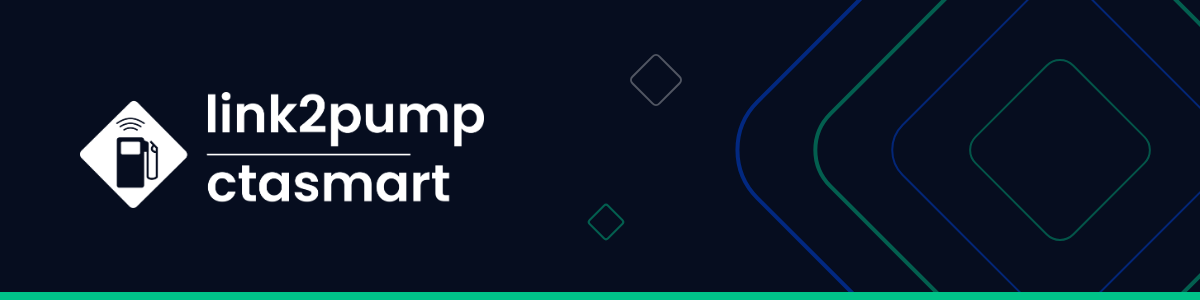

PARA:     dayane.hansen@transpveronese.com; matias.guidoni@transpveronese.com
CC:       
ASSUNTO:  Unificação das mensalidades de aluguel e licenciamento – ctasmart – VIACAO VERONESE LTDA e mais 1 cadastro(s)



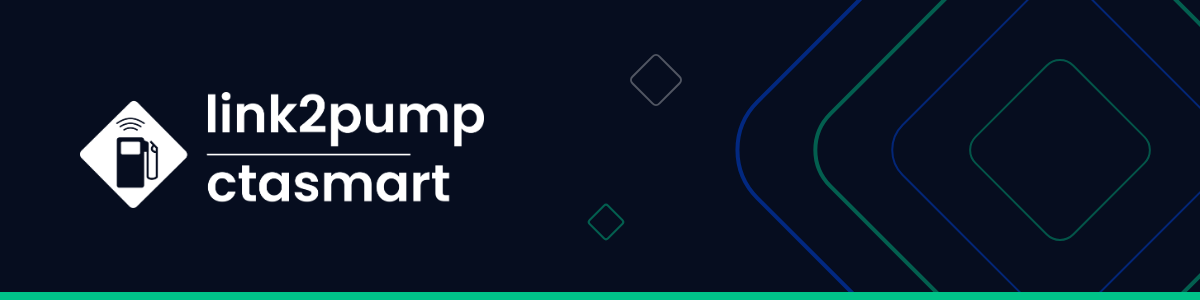

[Job(codigos=('005177', '005180'), nome='VIACAO VERONESE LTDA (+1)', para=['dayane.hansen@transpveronese.com', 'matias.guidoni@transpveronese.com'], cc=[], assunto='Unificação das mensalidades de aluguel e licenciamento – ctasmart – VIACAO VERONESE LTDA e mais 1 cadastro(s)', html='<!doctype html>\n<html lang="pt-BR"><head>\n<meta charset="utf-8">\n<meta name="viewport" content="width=device-width,initial-scale=1">\n<meta name="x-apple-disable-message-reformatting">\n<title>Unificação das mensalidades</title>\n<link href="https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500&family=Poppins:wght@600;700&display=swap" rel="stylesheet">\n<style>\n  @media (max-width:620px) { .cf-pad { padding:28px 22px !important; } .cf-h1 { font-size:21px !important; } }\n</style>\n</head>\n<body style="margin:0;padding:0;background:#F2F4F8">\n<div style="display:none;max-height:0;overflow:hidden;opacity:0;color:transparent">A partir do próximo ciclo de faturamento, as mensalidades de aluguel e l

In [5]:
fluxo.previa_email(c, previa)                               # o primeiro da fila
fluxo.previa_email(c, previa[previa.qtd_cadastros > 1])    # um que junta vários cadastros
# fluxo.previa_email(c, previa, codigo="1804")             # um cliente específico

## 5. Teste — vai só para você

⚠️ Use **só uma amostra** da prévia: com a prévia inteira chegariam os 338 e-mails na sua caixa.

Confira na caixa: remetente "ctasmart Financeiro", cabeçalho aparecendo, destinatários reais no
topo. Abra também no celular.

In [6]:
enviar = fluxo.criar_enviador(
    usuario="contato.financeiro@ctasmart.com.br",   # ou o seu e-mail, se a caixa for compartilhada
    senha_app=userdata.get("rotina"))

In [ ]:
amostra = pd.concat([previa[previa.qtd_cadastros == 1].head(2),
                     previa[previa.qtd_cadastros > 1].head(1)])

fluxo.disparar(Campanha.teste(**PARAM, para="yago.gutterres@ctasmart.com.br", reenviar=True),
               amostra, enviar, registro)

modo: TESTE -> tudo para paul.bioh@ctasmart.com.br
3 e-mail(s), 3 destinatário(s) enviados (em produção seriam 7).


Resultado(enviados=['005115', '004221', '005177+005180'], pulados=[], falhas=[], pendentes=[], destinatarios_usados=3, destinatarios_producao=7)

## 6. Produção — envia para os clientes

Só depois de conferir a prévia e o teste. Não tem desfazer.

Com o limite padrão de 450 destinatários por dia, a primeira execução envia parte da fila e
avisa quantos ficaram pendentes; continue no dia seguinte pela seção 7. Em conta Google
Workspace, dá para enviar tudo de uma vez com `Campanha.producao(**PARAM, teto_diario=1500)`.

In [7]:
fluxo.disparar(Campanha.producao(**PARAM), previa, enviar, registro)

   e-mail refeito sem os já avisados: 004551+004553 -> 004551
modo: PRODUCAO
106 e-mail(s), 257 destinatário(s) enviados (em produção seriam 257).
714 pulado(s):
   005115: já enviado nesta campanha
   004221: já enviado nesta campanha
   005107: já enviado nesta campanha
   005147: já enviado nesta campanha
   005194: já enviado nesta campanha
   003106: já enviado nesta campanha
   005149: já enviado nesta campanha
   002649: já enviado nesta campanha
   003759: já enviado nesta campanha
   005187: já enviado nesta campanha
   005210: já enviado nesta campanha
   005156: já enviado nesta campanha
   005146: já enviado nesta campanha
   005148: já enviado nesta campanha
   004338: já enviado nesta campanha


Resultado(enviados=['002441', '001621', '001752', '001828', '001127', '001691', '001831', '003504+003505', '000583', '000584', '003231', '002180', '002084', '000586', '004119', '001008', '001528', '000042', '003914', '000046', '000048', '000051', '001682', '002524', '002509', '002510', '000772', '003433', '002207', '001545', '001096', '004442', '000102', '004091', '000138', '000145', '000385', '002783', '005436', '003950', '002899', '004316', '002361', '000159', '003864', '002519+002518', '002520', '002517', '004399', '001638', '002098', '000176', '003790', '000643', '002363', '002091', '002597', '002328', '000231', '000234', '004596', '001534', '003456', '002744', '004127', '001592', '002075', '000256', '003015', '000275', '001765', '000277', '000924', '000280', '000281', '000478', '000822', '003797', '003325', '000829', '000286', '000304', '002502', '004551', '003357', '002251', '001715', '000992', '002909+002918+002910+002907+002911+002913+002915', '004100', '000317', '002036', '002

## 7. Retomar — no dia seguinte, ou se a sessão cair

Rode as seções **1**, **2** e a célula do `enviar = ...` da seção **5**, depois esta.
Usa a mesma prévia que você conferiu; o log pula quem já recebeu.

In [ ]:
previa = fluxo.ler_previa(PREVIA)

# opcional: mostra o que ainda falta, sem enviar
fluxo.disparar(Campanha.ensaio(**PARAM), previa, None, registro)

modo: DRY_RUN -> NADA será enviado; relatório do que sairia
0 e-mail(s), 0 destinatário(s) enviados (em produção seriam 0).
537 pulado(s):
   005115: já enviado nesta campanha
   004221: já enviado nesta campanha
   005107: já enviado nesta campanha
   005147: já enviado nesta campanha
   005194: já enviado nesta campanha
   003106: já enviado nesta campanha
   005149: já enviado nesta campanha
   002649: já enviado nesta campanha
   003759: já enviado nesta campanha
   005187: já enviado nesta campanha
   005210: já enviado nesta campanha
   005156: já enviado nesta campanha
   005146: já enviado nesta campanha
   005148: já enviado nesta campanha
   004338: já enviado nesta campanha


Resultado(enviados=[], pulados=[('005115', 'já enviado nesta campanha'), ('004221', 'já enviado nesta campanha'), ('005107', 'já enviado nesta campanha'), ('005147', 'já enviado nesta campanha'), ('005194', 'já enviado nesta campanha'), ('003106', 'já enviado nesta campanha'), ('005149', 'já enviado nesta campanha'), ('002649', 'já enviado nesta campanha'), ('003759', 'já enviado nesta campanha'), ('005187', 'já enviado nesta campanha'), ('005210', 'já enviado nesta campanha'), ('005156', 'já enviado nesta campanha'), ('005146', 'já enviado nesta campanha'), ('005148', 'já enviado nesta campanha'), ('004338', 'já enviado nesta campanha'), ('005182', 'já enviado nesta campanha'), ('001659', 'já enviado nesta campanha'), ('003127', 'já enviado nesta campanha'), ('003414', 'já enviado nesta campanha'), ('001716', 'já enviado nesta campanha'), ('005162', 'já enviado nesta campanha'), ('003869', 'já enviado nesta campanha'), ('005093', 'já enviado nesta campanha'), ('001542', 'já enviado ne

In [ ]:
fluxo.disparar(Campanha.producao(**PARAM), previa, enviar, registro)

modo: PRODUCAO
157 e-mail(s), 368 destinatário(s) enviados (em produção seriam 368).
186 pulado(s):
   005115: já enviado nesta campanha
   004221: já enviado nesta campanha
   005107: já enviado nesta campanha
   005147: já enviado nesta campanha
   005194: já enviado nesta campanha
   003106: já enviado nesta campanha
   005149: já enviado nesta campanha
   002649: já enviado nesta campanha
   003759: já enviado nesta campanha
   005187: já enviado nesta campanha
   005210: já enviado nesta campanha
   005156: já enviado nesta campanha
   005146: já enviado nesta campanha
   005148: já enviado nesta campanha
   004338: já enviado nesta campanha


Resultado(enviados=['001657', '001902', '002432', '000237', '002475', '001603', '000462+000464+000466', '002360', '003495', '001275', '003330', '003782', '004267', '000240', '003025', '001876', '003042', '003036', '003582', '000091', '000661', '001927', '003689', '000245', '004504', '001177', '003565', '002954', '004098', '001969', '004279+004276', '002969', '003078', '005300', '003254', '003765', '004054', '003221', '002041', '001755', '001442', '000792', '003566', '001940', '005288', '003489', '002883', '001110', '001990', '003884', '003065', '001973+001975', '001986', '001892', '003458', '000752', '000308', '004380', '003567', '000579', '004103', '003996', '003341', '003225', '001268', '002171', '001382', '004158', '001218', '004340', '001458', '003792', '004254', '005333', '001871', '001976', '002704', '004427', '002234', '002243', '001849', '001342', '003786', '003464', '003895', '005435', '001287', '004424', '004299', '002692', '003079', '001329', '003301', '001499', '002141', '0

## 8. Acompanhar

Falha não conta como enviado: rodar a seção 7 de novo tenta de novo só essas.

In [ ]:
log = pd.read_csv(f"{PASTA}/log.csv", dtype=str)
log = log[(log.id_campanha == PARAM["id_campanha"]) & (log.modo == "PRODUCAO")]
display(log.status.value_counts())
log[log.status == "FALHA"][["codigos", "nome", "erro"]]